In [3]:
import pandas as pd
import numpy as np
import re
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

# Helper to clean and binarize Yes/No predictions with trailing punctuation support
def clean_and_binarize(val):
    if pd.isna(val):
        return None
    cleaned = str(val).strip().lower()
    cleaned = re.sub(r'[\.\!\?]+$', '', cleaned).strip()
    if cleaned in ['yes', 'y', '1', 'true']:
        return 1
    elif cleaned in ['no', 'n', '0', 'false']:
        return 0
    else:
        return None

# 1. Load and pairwise concatenate
# Pair 1: Original Model(Qwen-3B) (from guessing1 and guessing2)
df_orig_1 = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/blank-evals-diff-models/guessing1.csv')
df_orig_2 = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/blank-evals-diff-models/guessing2.csv')
df_orig = pd.concat([df_orig_1, df_orig_2], ignore_index=True).drop_duplicates(subset=['Image_Id'], keep='first')
df_orig = df_orig.rename(columns={'Original': 'Original_Model'})

# Pair 2: Qwen-2B Model (from guessing1-qwen-2b and guessing2-qwen-2b)
df_qwen_1 = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/blank-evals-diff-models/guessing1-qwen-2b.csv')
df_qwen_2 = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/blank-evals-diff-models/guessing2-qwen-2b.csv')
df_qwen = pd.concat([df_qwen_1, df_qwen_2], ignore_index=True).drop_duplicates(subset=['Image_Id'], keep='first')
df_qwen = df_qwen.rename(columns={'Original': 'Qwen-2B'})

# Pair 3: Smol-2.2B Model (from guessing1-smol-2.2b and guessing2-smol-2.2b)
df_smol_1 = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/blank-evals-diff-models/guessing1-smol-2.2b.csv')
df_smol_2 = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/blank-evals-diff-models/guessing2-smol-2.2b.csv')
df_smol = pd.concat([df_smol_1, df_smol_2], ignore_index=True).drop_duplicates(subset=['Image_Id'], keep='first')
df_smol = df_smol.rename(columns={'Original': 'Smol-2.2B'})

# 2. Merge all 3 into one consolidated DataFrame
merged_df = pd.merge(df_orig[['Image_Id', 'Ground_truth', 'Original_Model']], df_qwen[['Image_Id', 'Qwen-2B']], on='Image_Id', how='inner')
merged_df = pd.merge(merged_df, df_smol[['Image_Id', 'Smol-2.2B']], on='Image_Id', how='inner')

# Save to guessing-diff-models.csv
merged_df.to_csv('guessing-diff-models.csv', index=False)
print("Saved merged file to guessing-diff-models.csv")

# 3. Calculate Metrics
gt_col = 'Ground_truth'
model_cols = ['Original_Model', 'Qwen-2B', 'Smol-2.2B']
metrics_summary = []

for model_name in model_cols:
    temp_df = pd.DataFrame({
        'y_true_raw': merged_df[gt_col],
        'y_pred_raw': merged_df[model_name]
    })
    
    temp_df['y_true'] = temp_df['y_true_raw'].apply(clean_and_binarize)
    temp_df['y_pred'] = temp_df['y_pred_raw'].apply(clean_and_binarize)
    
    clean_df = temp_df.dropna()
    
    y_true = clean_df['y_true'].astype(int).values
    y_pred = clean_df['y_pred'].astype(int).values
    
    if len(y_true) == 0:
        continue
        
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    
    metrics_summary.append({
        "MODEL": model_name,
        "Valid_Rows": len(y_true),
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "FPR (False Positive Rate)": fpr,
        "FNR (False Negative Rate)": fnr
    })

df_metrics_output = pd.DataFrame(metrics_summary)
display(df_metrics_output)

Saved merged file to guessing-diff-models.csv


,MODEL,Valid_Rows,TP,TN,FP,FN,Accuracy,Precision,Recall,F1_Score,FPR (False Positive Rate),FNR (False Negative Rate)
0,Original_Model,989,0,989,0,0,1.0,0.0,0.0,0.0,0.0,0.0
1,Qwen-2B,989,0,989,0,0,1.0,0.0,0.0,0.0,0.0,0.0
2,Smol-2.2B,989,0,989,0,0,1.0,0.0,0.0,0.0,0.0,0.0


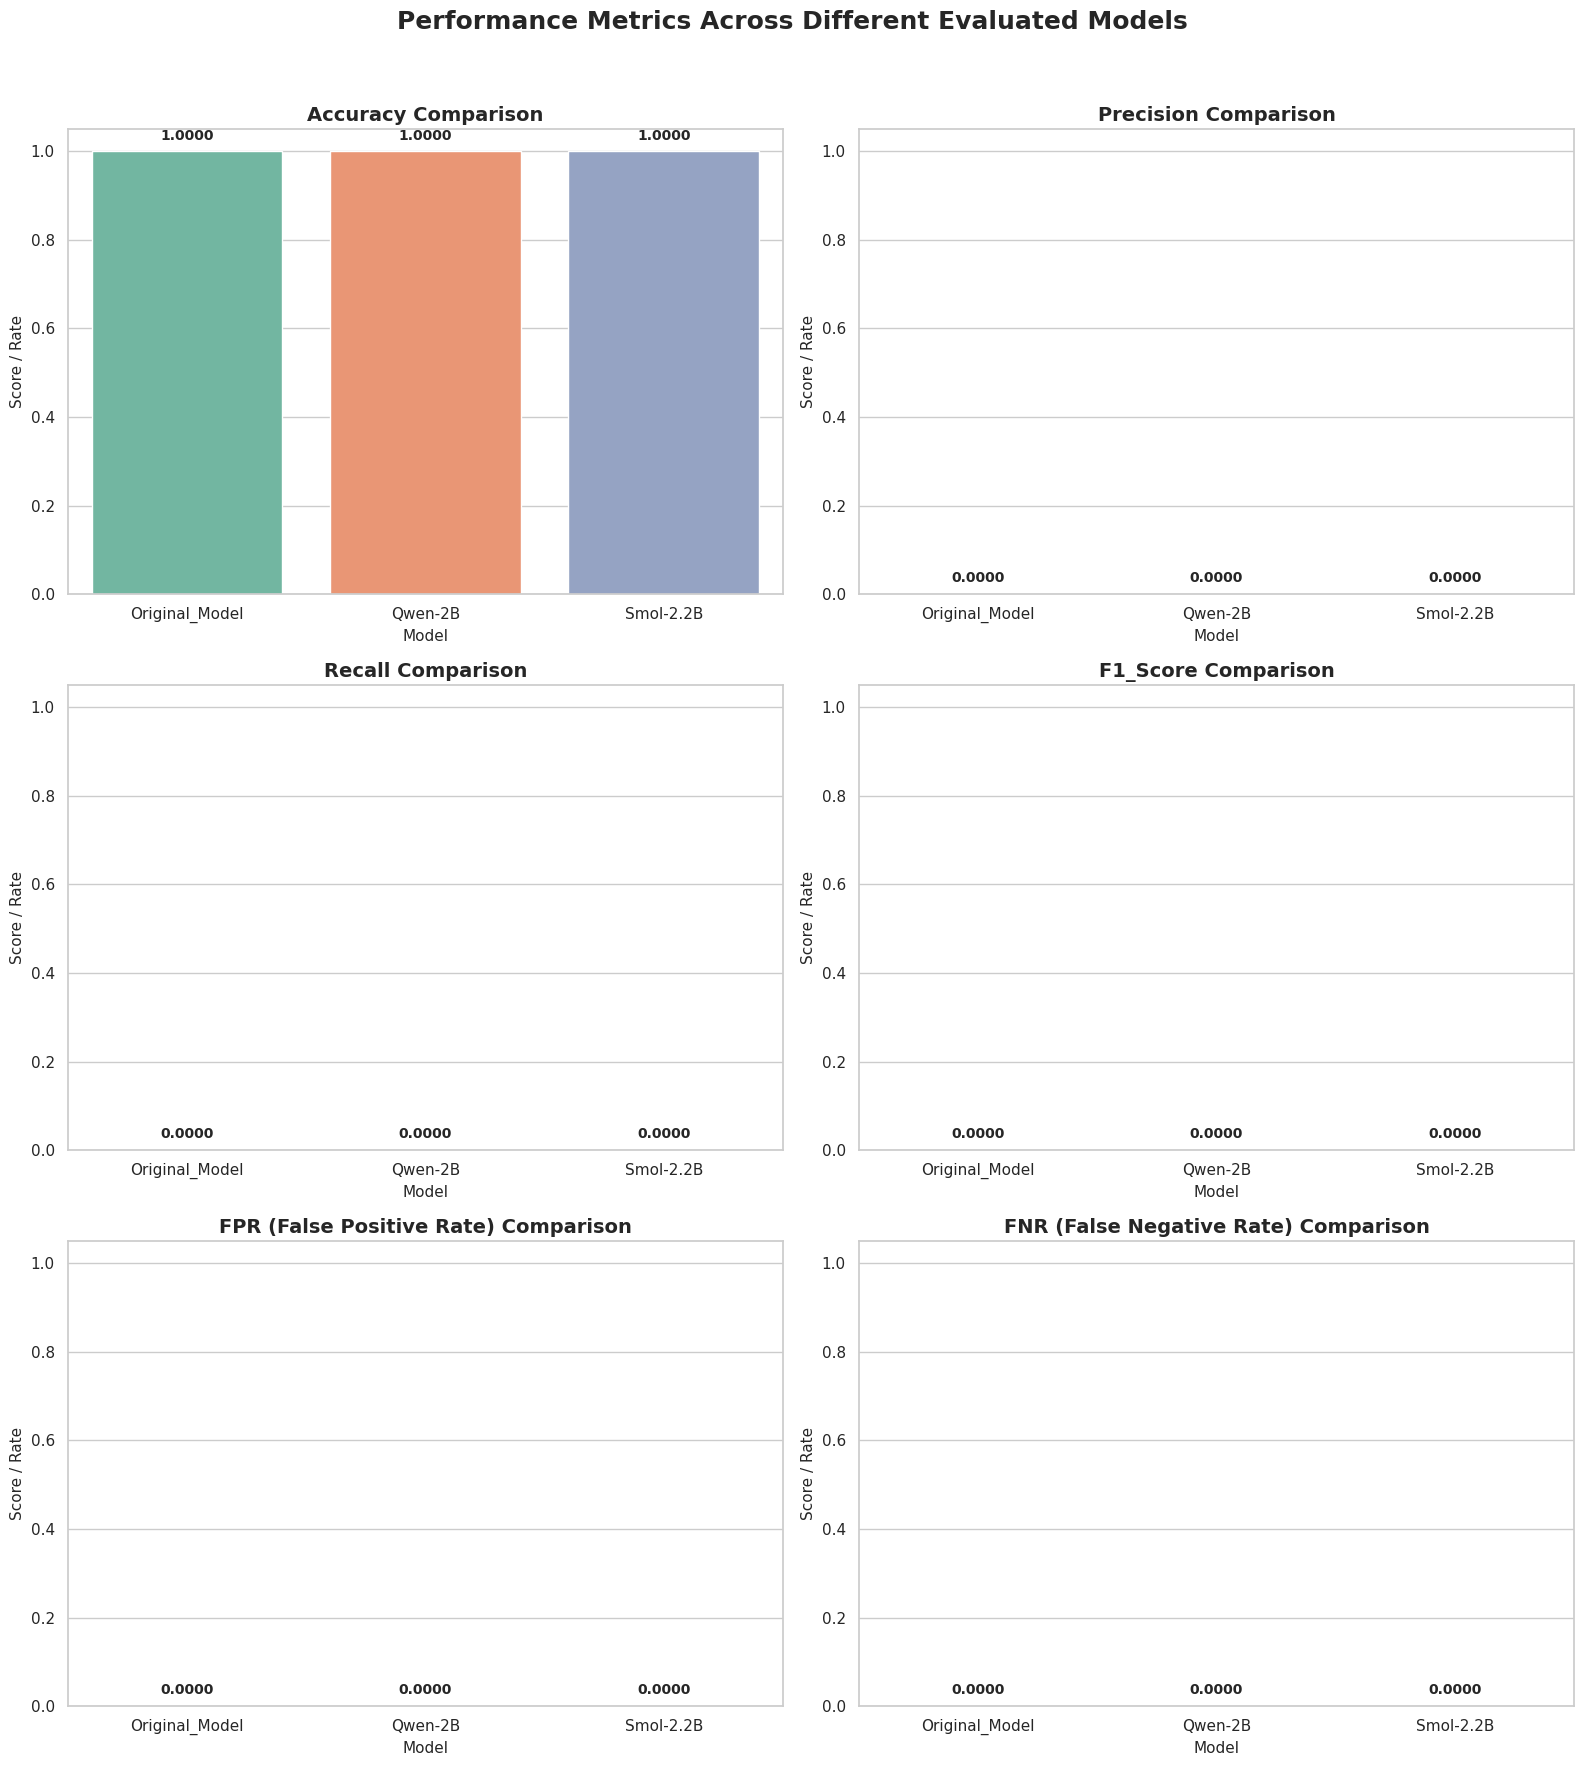

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Extract lists of metrics to plot
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'FPR (False Positive Rate)', 'FNR (False Negative Rate)']
models = df_metrics_output['MODEL'].tolist()

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

# Generate a unique color palette for the models
colors = sns.color_palette("Set2", len(models))

for i, metric in enumerate(metrics_to_plot):
    values = df_metrics_output[metric].tolist()
    
    # Plot bar chart for current metric
    sns.barplot(x=models, y=values, ax=axes[i], palette="Set2", hue=models, legend=False)
    
    axes[i].set_title(f'{metric} Comparison', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('Score / Rate', fontsize=11)
    axes[i].set_ylim(0, 1.05)
    axes[i].set_xlabel('Model', fontsize=11)
    
    # Add text labels on top of the bars
    for bar in axes[i].patches:
        yval = bar.get_height()
        axes[i].text(
            bar.get_x() + bar.get_width()/2.0, 
            yval + 0.02, 
            f"{yval:.4f}", 
            ha='center', 
            va='bottom', 
            fontsize=10, 
            fontweight='bold'
        )

plt.suptitle('Performance Metrics Across Different Evaluated Models', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()